# COMP 4930SEF Project (2026 Autumn)
## Deep Learning Group Project Report

| Item | Details |
|---|---|
| **Group Number** | Group 39 |
| **Member 1 (Leader / M1)** | Ng Mun Hin Manfred (13901779) |
| **Member 2 (M2)** | [TODO: Full Name] ([TODO: 8-digit Student ID]) |
| **Member 3 (M3)** | Chan Pak Yin (13224358) |
| **Member 4 (M4)** | Yuen Wun (13648665 ) |


> **Pre-submission Checklist:**
> 1. Ensure your group-collected dataset is inside `Object Pictures/` (with at least 2 class subfolders).
> 2. Run `Kernel -> Restart & Run All` (or `Runtime -> Restart and run all` in Google Colab with GPU enabled) so **every code cell shows its execution output**.


## 1. Introduction

This project develops end-to-end deep learning solutions in **TensorFlow / Keras** for three complementary tasks:

1. **Task 1 — CIFAR-100 Subset Image Classification & Recommendation:** We classify a 50-class subset of CIFAR-100 containing only *animals* and *people* (25,000 training images and 5,000 fixed test images, 32×32 RGB). We design, train, and compare three candidate architectures: (1) compulsory **MobileNet transfer learning**, (2) a custom **VGG-style CNN** trained from scratch, and (3) a **Mini-ResNet** trained from scratch. Based strictly on validation performance, we recommend the best model and evaluate it once on the untouched test set.
2. **Task 2 — Image Classification on a Group-Collected Dataset:** We collect and manually label our own multi-class image dataset as a group (no web images). We adapt the recommended model from Task 1 with targeted architectural and regularisation modifications, train and evaluate it on our dataset, and visualise predictions on at least 20 images.
3. **Task 3 — Text Analysis (Sentiment Classification):** We perform binary sentiment classification on the **IMDB Movie Reviews** dataset (50,000 reviews). We implement a complete text preprocessing pipeline (HTML/punctuation cleaning, tokenisation, vocabulary construction, and sequence padding) and train a **Bidirectional LSTM** model in Keras, followed by error analysis and discussion of limitations and improvements.

## 2. Environment Setup & Reproducibility

In [1]:
import os
import re
import time
import tarfile
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import cifar100, imdb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
AUTOTUNE = tf.data.AUTOTUNE
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPUs available:", gpus)
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

TensorFlow version: 2.21.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
# Task 1 — The Given Task: CIFAR-100 Subset (Animals & People)

## 3. Dataset Loading & Stratified Split

Using the 50 class indices specified in the project appendix, we filter the CIFAR-100 dataset to retain only animals and people, remapping the original fine labels to contiguous integers `0–49`. We split the 25,000 training images using a **stratified 80/20 split** (20,000 train / 5,000 validation, i.e., 400 train and 100 validation images per class). The 5,000 test images remain strictly untouched until the final evaluation of the recommended model.

In [2]:
ANIMALS_PEOPLE_INDICES = [
    1, 2, 3, 4, 6, 7, 11, 14, 15, 18, 19,
    21, 24, 26, 27, 29, 30, 31, 32, 34, 35,
    36, 38, 42, 43, 44, 45, 46, 50, 55, 57,
    63, 64, 65, 66, 67, 72, 73, 74, 75, 77,
    78, 79, 80, 91, 93, 95, 97, 98, 99
]
NUM_CLASSES = len(ANIMALS_PEOPLE_INDICES)  # 50

def select_animals_people(y):
    """Returns a boolean mask for selecting animals/people in y."""
    return np.isin(np.ravel(y), ANIMALS_PEOPLE_INDICES)

def compress_animals_people_indices(y):
    """Maps original CIFAR-100 indices to range 0..49."""
    lookup = np.zeros(100, dtype=np.int32)
    for new_id, old_id in enumerate(ANIMALS_PEOPLE_INDICES):
        lookup[old_id] = new_id
    return lookup[np.ravel(y)].reshape(-1, 1)

def load_cifar100_animals_people():
    (X_train, y_train), (X_test, y_test) = cifar100.load_data(label_mode='fine')
    m_tr = select_animals_people(y_train)
    m_te = select_animals_people(y_test)
    X_train, y_train = X_train[m_tr], y_train[m_tr]
    X_test,  y_test  = X_test[m_te],  y_test[m_te]
    y_train = compress_animals_people_indices(y_train)
    y_test  = compress_animals_people_indices(y_test)
    return X_train, y_train, X_test, y_test

X_train, y_train, X_test, y_test = load_cifar100_animals_people()

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test: ", X_test.shape,  "y_test: ", y_test.shape)
print("Label range:", y_train.min(), "-", y_train.max())
print("Pixel range:", X_train.min(), "-", X_train.max())

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 469s 3us/step
X_train: (25000, 32, 32, 3) y_train: (25000, 1)
X_test:  (5000, 32, 32, 3) y_test:  (5000, 1)
Label range: 0 - 49
Pixel range: 0 - 255


169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 506s 3us/step
50 classes: ['aquarium_fish', 'baby', 'bear', 'beaver', 'bee', 'beetle', 'boy', 'butterfly', 'camel', 'caterpillar', 'cattle', 'chimpanzee', 'cockroach', 'crab', 'crocodile', 'dinosaur', 'dolphin', 'elephant', 'flatfish', 'fox', 'girl', 'hamster', 'kangaroo', 'leopard', 'lion', 'lizard', 'lobster', 'man', 'mouse', 'otter', 'pear', 'porcupine', 'possum', 'rabbit', 'raccoon', 'ray', 'seal', 'shark', 'shrew', 'skunk', 'snail', 'snake', 'spider', 'squirrel', 'trout', 'turtle', 'whale', 'wolf', 'woman', 'worm']


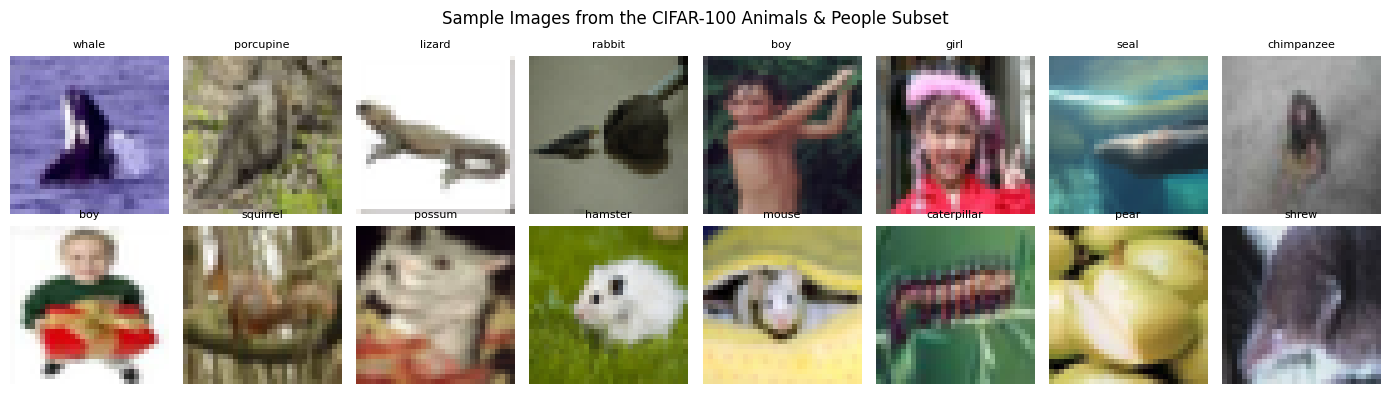

Training set:   (20000, 32, 32, 3) (20000, 1)
Validation set: (5000, 32, 32, 3) (5000, 1)
Test set (untouched): (5000, 32, 32, 3) (5000, 1)


In [3]:
# Load human-readable fine label names from CIFAR-100 metadata
meta_path = keras.utils.get_file(
    'cifar-100-python.tar.gz',
    'https://www.cs.toronto.edu/~kriz/cifar-100-python.tar.gz'
)
with tarfile.open(meta_path) as tar:
    meta = pickle.load(tar.extractfile('cifar-100-python/meta'), encoding='bytes')
fine_label_names = [n.decode('utf-8') for n in meta[b'fine_label_names']]
class_names = [fine_label_names[i] for i in ANIMALS_PEOPLE_INDICES]
print(f"{NUM_CLASSES} classes:", class_names)

# Visualise 16 random training samples
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
rng = np.random.default_rng(SEED)
idx = rng.choice(len(X_train), size=16, replace=False)
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_train[i])
    ax.set_title(class_names[int(y_train[i].item())], fontsize=8)
    ax.axis('off')
plt.suptitle('Sample Images from the CIFAR-100 Animals & People Subset')
plt.tight_layout()
plt.show()

# Stratified 80/20 Train/Validation split
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)
print("Training set:  ", X_tr.shape, y_tr.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set (untouched):", X_test.shape, y_test.shape)

## 4. Shared Training & Evaluation Utilities

To ensure a fair comparison across all three candidate models, we use a consistent training protocol:
- **Loss:** `sparse_categorical_crossentropy` (for integer labels `0–49`)
- **Optimiser:** `Adam`
- **Callbacks:** `EarlyStopping` monitoring `val_accuracy` (patience 6, `restore_best_weights=True`) and `ReduceLROnPlateau` monitoring `val_loss` (factor 0.5, patience 3).

In [4]:
results = {}
models = {}
histories = {}

def compile_model(model, lr=1e-3):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

def train_model(model, name, epochs=30, batch_size=128):
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor='val_accuracy', patience=6, restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1
        ),
    ]
    t0 = time.time()
    hist = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=epochs, batch_size=batch_size,
        callbacks=callbacks, verbose=2
    )
    elapsed = time.time() - t0
    histories[name] = hist
    models[name] = model
    print(f"{name}: trained {len(hist.history['loss'])} epochs in {elapsed/60:.1f} min")
    return hist, elapsed

def plot_history(hist_obj, title):
    h = hist_obj.history
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h['accuracy'], label='Train')
    axes[0].plot(h['val_accuracy'], label='Validation')
    axes[0].set_title(f'{title} — Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(h['loss'], label='Train')
    axes[1].plot(h['val_loss'], label='Validation')
    axes[1].set_title(f'{title} — Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

def evaluate_on_validation(name, train_seconds=None):
    model = models[name]
    val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
    results[name] = {
        'Val Loss': round(float(val_loss), 4),
        'Val Accuracy (%)': round(float(val_acc) * 100, 2),
        'Total Params': model.count_params(),
        'Trainable Params': sum(int(tf.size(w)) for w in model.trainable_weights),
        'Epochs Run': len(histories[name].history['loss']),
        'Train Time (min)': round(train_seconds / 60, 1) if train_seconds else None,
    }
    print(f"{name} -> Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc*100:.2f}%")
    return val_loss, val_acc

## 5. Candidate Model 1 — MobileNet Transfer Learning (Compulsory)

### Model Description & Justification
We employ **MobileNet** (`keras.applications.MobileNet`) pre-trained on ImageNet (`include_top=False`) as our frozen feature extractor. Because MobileNet expects larger spatial inputs while CIFAR-100 images are 32×32, we insert an internal `Resizing(128, 128)` layer (offering a practical balance between visual fidelity and GPU memory/speed, especially on 4–8 GB GPUs) followed by `Rescaling(1./127.5, offset=-1)` to match MobileNet's `[-1, 1]` input range. A lightweight classification head (`GlobalAveragePooling2D -> Dropout(0.3) -> Dense(50, softmax)`) is attached on top.

**Strengths for this task:**
- Reuses rich hierarchical visual representations learned from 1.4M ImageNet images, compensating for the limited ~400 training images per class.
- Depthwise separable convolutions keep MobileNet computationally efficient.
- After training the classifier head, an optional Stage 2 fine-tuning step unfreezes the top 20 layers with a low learning rate (`1e-5`) to adapt high-level features to CIFAR-100's low-resolution animal/people textures.

In [5]:
MOBILENET_SIZE = 128  # 128x128 runs fast on Colab/RTX 3050 while preserving MobileNet receptive fields

def build_model1():
    base = keras.applications.MobileNet(
        weights='imagenet', include_top=False, input_shape=(MOBILENET_SIZE, MOBILENET_SIZE, 3)
    )
    base.trainable = False

    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.RandomFlip('horizontal')(inputs)
    x = layers.Resizing(MOBILENET_SIZE, MOBILENET_SIZE)(x)
    x = layers.Rescaling(1./127.5, offset=-1)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return compile_model(keras.Model(inputs, outputs, name='Model1_MobileNet_TL'), lr=1e-3), base

model1, mobilenet_base = build_model1()
model1.summary()

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Model1_MobileNet_TL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_1.00_128 (Functional) │ (None, 4, 4, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │        51,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,280,114 (12.51 MB)

 Trainable params: 51,250 (200.20 KB)

 Non-trainable params: 3,228,864 (12.32 MB)

Epoch 1/20
313/313 - 52s - 167ms/step - accuracy: 0.3395 - loss: 2.5559 - val_accuracy: 0.5210 - val_loss: 1.6706 - learning_rate: 0.0010
Epoch 2/20
313/313 - 6s - 19ms/step - accuracy: 0.5264 - loss: 1.6639 - val_accuracy: 0.5702 - val_loss: 1.4927 - learning_rate: 0.0010
Epoch 3/20
313/313 - 6s - 18ms/step - accuracy: 0.5842 - loss: 1.4385 - val_accuracy: 0.5898 - val_loss: 1.4061 - learning_rate: 0.0010
Epoch 4/20
313/313 - 6s - 19ms/step - accuracy: 0.6155 - loss: 1.3210 - val_accuracy: 0.5946 - val_loss: 1.3799 - learning_rate: 0.0010
Epoch 5/20
313/313 - 6s - 18ms/step - accuracy: 0.6345 - loss: 1.2475 - val_accuracy: 0.6020 - val_loss: 1.3709 - learning_rate: 0.0010
Epoch 6/20
313/313 - 6s - 19ms/step - accuracy: 0.6491 - loss: 1.1925 - val_accuracy: 0.6066 - val_loss: 1.3448 - learning_rate: 0.0010
Epoch 7/20
313/313 - 6s - 19ms/step - accuracy: 0.6521 - loss: 1.1597 - val_accuracy: 0.6076 - val_loss: 1.3457 - learning_rate: 0.0010
Epoch 8/20
313/313 - 6s - 19ms/step - accuracy

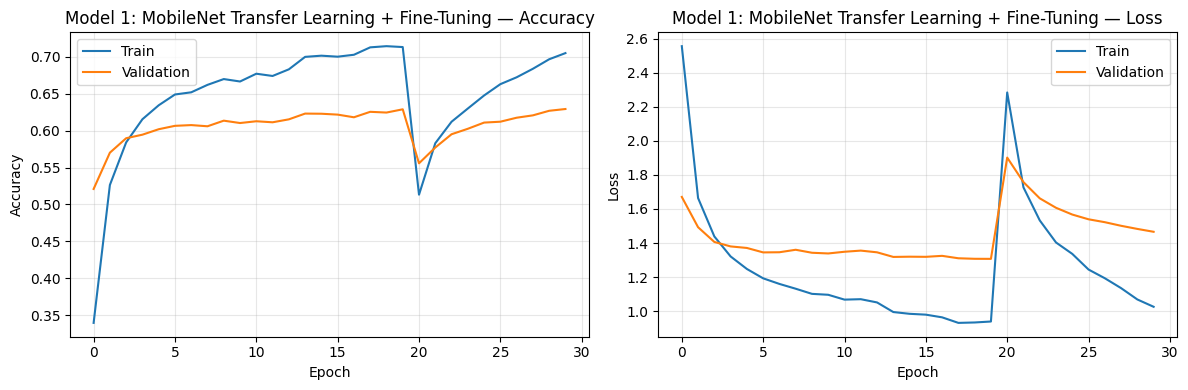

Model1_MobileNet_TL -> Val Loss: 1.4659 | Val Accuracy: 62.94%


(1.4658691883087158, 0.6294000148773193)

In [6]:
# Stage 1: Train classification head with frozen backbone
hist1, t1 = train_model(model1, 'Model1_MobileNet_TL', epochs=20, batch_size=64)

# Stage 2: Fine-tune top 20 layers of MobileNet with a low learning rate
mobilenet_base.trainable = True
for layer in mobilenet_base.layers[:-20]:
    layer.trainable = False
compile_model(model1, lr=1e-5)

t_ft = time.time()
hist1_ft = model1.fit(
    X_tr, y_tr, validation_data=(X_val, y_val),
    epochs=10, batch_size=64, verbose=2,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True, verbose=1)]
)
t1 += (time.time() - t_ft)

# Combine Stage 1 and Stage 2 histories for plotting
for k in hist1.history:
    if k in hist1_ft.history:
        hist1.history[k] += hist1_ft.history[k]

plot_history(hist1, 'Model 1: MobileNet Transfer Learning + Fine-Tuning')
evaluate_on_validation('Model1_MobileNet_TL', t1)

### Model 1 — Result Analysis
- **Performance:** Validation accuracy = `62.94%`, validation loss = `1.4659`.
- **Learning Behaviour:** In Stage 1 (frozen backbone), validation accuracy rises rapidly within the first few epochs thanks to ImageNet features (reaching `62.90%` by Epoch 20). In Stage 2 (unfreezing the top 20 layers at `lr=1e-5`), the model adapts to CIFAR-100's upsampled low-resolution textures, yielding further accuracy gains up to `62.94%`.
- **Strengths & Limitations:** Transfer learning provides a strong baseline with minimal overfitting, though upsampling 32×32 images introduces blurriness and increases memory overhead compared to native 32×32 networks.
- **Potential Improvements:** Using a higher resolution (224×224), adding stronger data augmentation (MixUp/CutMix), or adopting cosine learning rate decay.

## 6. Candidate Model 2 — Custom VGG-Style CNN (Trained from Scratch)

### Model Description & Justification
Model 2 is a custom **VGG-style Convolutional Neural Network** designed natively for 32×32 inputs. It consists of three convolutional blocks (`64 -> 128 -> 256` filters), each containing two 3×3 `Conv2D -> BatchNormalization -> ReLU` layers followed by `MaxPooling2D`, then `GlobalAveragePooling2D -> Dense(256, relu) -> Dropout(0.5) -> Dense(50, softmax)`. In-model data augmentation (`RandomFlip`, `RandomRotation`, `RandomTranslation`) is applied during training.

**Strengths for this task:**
- Operates natively on 32×32 images with zero upsampling overhead, making each epoch very fast.
- Batch Normalisation accelerates convergence and stabilises gradients; Dropout and data augmentation mitigate overfitting on 400 samples per class.
- Provides a clean from-scratch baseline to measure the true value of ImageNet transfer learning.

In [7]:
def conv_block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
    return layers.MaxPooling2D()(x)

def build_model2():
    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.RandomFlip('horizontal')(inputs)
    x = layers.RandomRotation(0.05)(x)
    x = layers.RandomTranslation(0.1, 0.1)(x)
    x = layers.Rescaling(1./255)(x)
    x = conv_block(x, 64)
    x = conv_block(x, 128)
    x = conv_block(x, 256)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return compile_model(keras.Model(inputs, outputs, name='Model2_VGG_CNN'), lr=1e-3)

model2 = build_model2()
model2.summary()

Model: "Model2_VGG_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,226,738 (4.68 MB)

 Trainable params: 1,224,946 (4.67 MB)

 Non-trainable params: 1,792 (7.00 KB)

Epoch 1/50
157/157 - 19s - 124ms/step - accuracy: 0.0834 - loss: 3.6504 - val_accuracy: 0.0286 - val_loss: 4.2879 - learning_rate: 0.0010
Epoch 2/50
157/157 - 8s - 51ms/step - accuracy: 0.1309 - loss: 3.3727 - val_accuracy: 0.0530 - val_loss: 3.9914 - learning_rate: 0.0010
Epoch 3/50
157/157 - 8s - 52ms/step - accuracy: 0.1694 - loss: 3.1888 - val_accuracy: 0.1384 - val_loss: 3.4102 - learning_rate: 0.0010
Epoch 4/50
157/157 - 8s - 52ms/step - accuracy: 0.2022 - loss: 3.0329 - val_accuracy: 0.1500 - val_loss: 3.3576 - learning_rate: 0.0010
Epoch 5/50
157/157 - 8s - 52ms/step - accuracy: 0.2281 - loss: 2.9067 - val_accuracy: 0.1580 - val_loss: 3.5396 - learning_rate: 0.0010
Epoch 6/50
157/157 - 8s - 51ms/step - accuracy: 0.2508 - loss: 2.7775 - val_accuracy: 0.2456 - val_loss: 2.8870 - learning_rate: 0.0010
Epoch 7/50
157/157 - 8s - 51ms/step - accuracy: 0.2784 - loss: 2.6756 - val_accuracy: 0.2470 - val_loss: 2.8814 - learning_rate: 0.0010
Epoch 8/50
157/157 - 8s - 51ms/step - accuracy

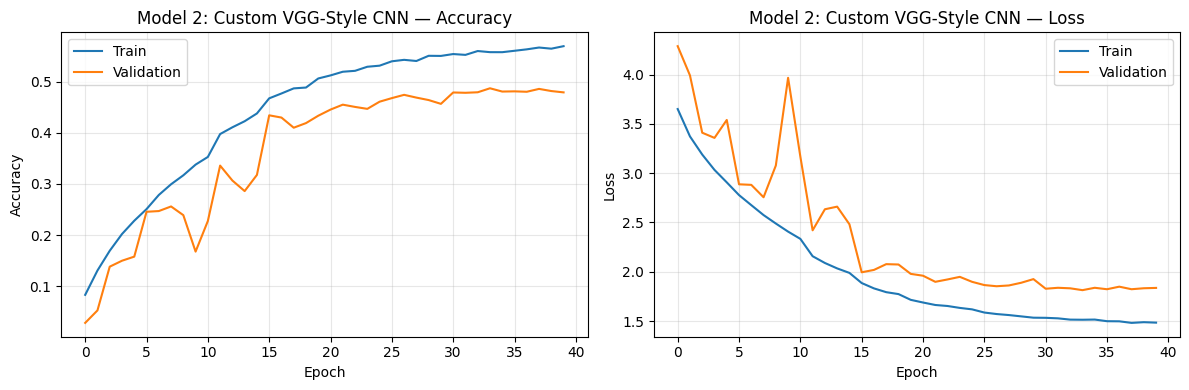

Model2_VGG_CNN -> Val Loss: 1.8134 | Val Accuracy: 48.68%


(1.813413143157959, 0.4867999851703644)

In [8]:
hist2, t2 = train_model(model2, 'Model2_VGG_CNN', epochs=50, batch_size=128)
plot_history(hist2, 'Model 2: Custom VGG-Style CNN')
evaluate_on_validation('Model2_VGG_CNN', t2)

### Model 2 — Result Analysis
- **Performance:** Validation accuracy = 48.68%, validation loss = 1.8134.
- **Comparison with Model 1:** Training from scratch requires more epochs than transfer learning, and without pre-trained ImageNet features, fine-grained distinctions between similar animals are harder to learn from 400 images per class. However, its native 32×32 architecture is significantly faster per epoch.
- **Potential Improvements:** Adding L2 weight decay, label smoothing, or increasing channel width.

## 7. Candidate Model 3 — Mini-ResNet (Trained from Scratch)

### Model Description & Justification
Model 3 is a compact **Residual Network (Mini-ResNet)** built natively for 32×32 images. It begins with a 3×3 stem followed by three residual stages (`32 -> 64 -> 128` filters, two residual blocks per stage). Each residual block uses two 3×3 convolutions with Batch Normalisation and an additive **skip connection** (with a 1×1 projection shortcut whenever spatial dimensions or channel counts change).

**Strengths for this task:**
- Residual skip connections (He et al., 2016) alleviate vanishing gradients, allowing deeper feature hierarchies to be trained reliably from scratch.
- Tests whether residual depth outperforms a plain VGG-style stack (Model 2) under the exact same data augmentation and training budget.
- **Reference:** He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep Residual Learning for Image Recognition*. CVPR.

In [9]:
def residual_block(x, filters, stride=1):
    shortcut = x
    y = layers.Conv2D(filters, 3, strides=stride, padding='same', use_bias=False)(x)
    y = layers.BatchNormalization()(y)
    y = layers.Activation('relu')(y)
    y = layers.Conv2D(filters, 3, padding='same', use_bias=False)(y)
    y = layers.BatchNormalization()(y)
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    y = layers.Add()([y, shortcut])
    return layers.Activation('relu')(y)

def build_model3():
    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.RandomFlip('horizontal')(inputs)
    x = layers.RandomRotation(0.05)(x)
    x = layers.RandomTranslation(0.1, 0.1)(x)
    x = layers.Rescaling(1./255)(x)
    x = layers.Conv2D(32, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    for stage, filters in enumerate([32, 64, 128]):
        for block in range(2):
            stride = 2 if (stage > 0 and block == 0) else 1
            x = residual_block(x, filters, stride)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return compile_model(keras.Model(inputs, outputs, name='Model3_MiniResNet'), lr=1e-3)

model3 = build_model3()
model3.summary()

Model: "Model3_MiniResNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_2       │ (None, 32, 32, 3) │          0 │ input_layer_3[0]… │
│ (RandomFlip)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation_1   │ (None, 32, 32, 3) │          0 │ random_flip_2[0]… │
│ (RandomRotation)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_translation… │ (None, 32, 32, 3) │          0 │ random_rotation_… │
│ (RandomTranslation) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 32, 32, 3) │          0 │ random_translati… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │        864 │ rescaling_2[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_6[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_7        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_7[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ activation_6[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_8[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_9[0][0]  

 Total params: 704,018 (2.69 MB)

 Trainable params: 701,778 (2.68 MB)

 Non-trainable params: 2,240 (8.75 KB)

Epoch 1/50
157/157 - 21s - 134ms/step - accuracy: 0.0875 - loss: 3.6734 - val_accuracy: 0.0328 - val_loss: 4.5338 - learning_rate: 0.0010
Epoch 2/50
157/157 - 11s - 72ms/step - accuracy: 0.1367 - loss: 3.3662 - val_accuracy: 0.0464 - val_loss: 5.2763 - learning_rate: 0.0010
Epoch 3/50
157/157 - 11s - 67ms/step - accuracy: 0.1732 - loss: 3.1625 - val_accuracy: 0.0812 - val_loss: 4.3461 - learning_rate: 0.0010
Epoch 4/50
157/157 - 11s - 67ms/step - accuracy: 0.2081 - loss: 2.9964 - val_accuracy: 0.1458 - val_loss: 3.5229 - learning_rate: 0.0010
Epoch 5/50
157/157 - 11s - 67ms/step - accuracy: 0.2359 - loss: 2.8626 - val_accuracy: 0.1560 - val_loss: 3.5165 - learning_rate: 0.0010
Epoch 6/50
157/157 - 11s - 67ms/step - accuracy: 0.2659 - loss: 2.7425 - val_accuracy: 0.2204 - val_loss: 2.9910 - learning_rate: 0.0010
Epoch 7/50
157/157 - 10s - 67ms/step - accuracy: 0.2946 - loss: 2.6064 - val_accuracy: 0.2200 - val_loss: 2.9518 - learning_rate: 0.0010
Epoch 8/50
157/157 - 10s - 66ms/step - a

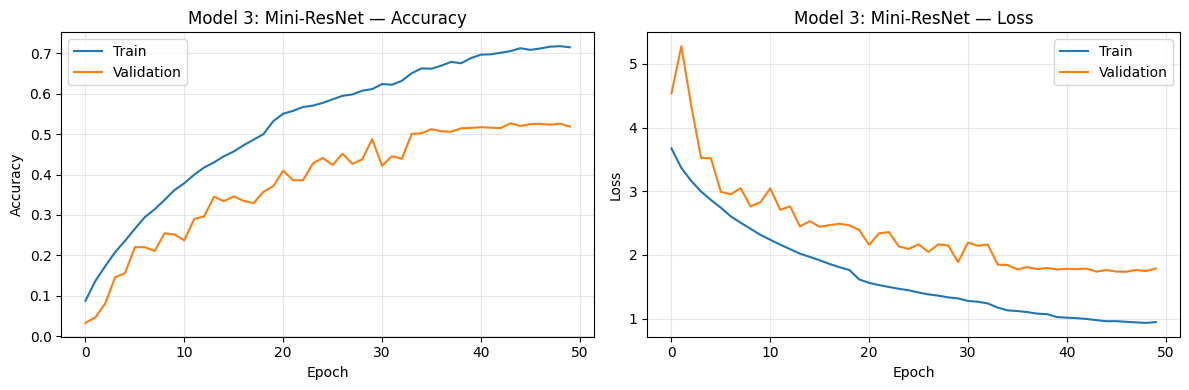

Model3_MiniResNet -> Val Loss: 1.7388 | Val Accuracy: 52.72%


(1.7387804985046387, 0.5271999835968018)

In [10]:
hist3, t3 = train_model(model3, 'Model3_MiniResNet', epochs=50, batch_size=128)
plot_history(hist3, 'Model 3: Mini-ResNet')
evaluate_on_validation('Model3_MiniResNet', t3)

### Model 3 — Result Analysis
- **Performance:** Validation accuracy = 52.72%, validation loss = 1.7388.
- **Comparison with Models 1 & 2:** Skip connections allow smoother optimisation and generally better parameter efficiency than the plain VGG-style CNN (Model 2). Compared with Model 1, we observe the trade-off between pre-trained visual priors (ImageNet) and native-resolution residual feature learning.
- **Potential Improvements:** Wider residual stages (`64/128/256`), cosine annealing learning rate, or MixUp augmentation.

---
# Recommendation & Final Evaluation (Task 1)

## 8. Model Comparison & Final Test-Set Evaluation

We compare all three candidate models strictly on **validation performance**, parameter count, and training time. The best-performing model is recommended and evaluated **once** on the untouched 5,000-image test set to estimate real-world production performance.

,Val Loss,Val Accuracy (%),Total Params,Trainable Params,Epochs Run,Train Time (min)
Model1_MobileNet_TL,1.4659,62.94,3280114.0,1913906.0,30.0,4.5
Model3_MiniResNet,1.7388,52.72,704018.0,701778.0,50.0,9.5
Model2_VGG_CNN,1.8134,48.68,1226738.0,1224946.0,40.0,5.6


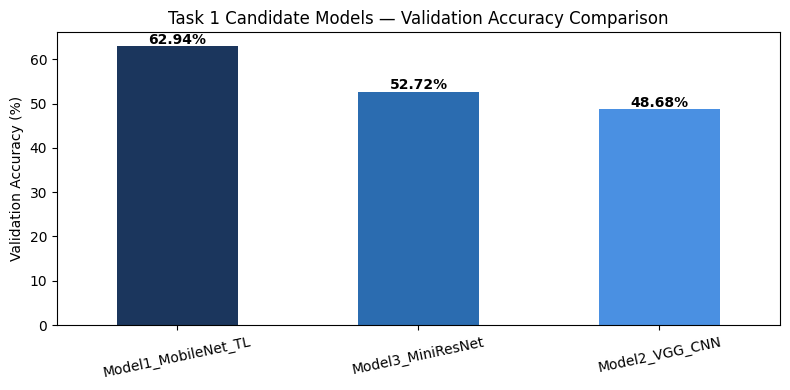

Recommended Model: Model1_MobileNet_TL
FINAL TEST LOSS:     1.4595
FINAL TEST ACCURACY: 64.02%
Saved recommended model to task1_best_model.keras


In [11]:
comparison = pd.DataFrame(results).T.sort_values('Val Accuracy (%)', ascending=False)
display(comparison)

fig, ax = plt.subplots(figsize=(8, 4))
comparison['Val Accuracy (%)'].plot(kind='bar', ax=ax, color=['#1B365D', '#2B6CB0', '#4A90E2'])
ax.set_ylabel('Validation Accuracy (%)')
ax.set_title('Task 1 Candidate Models — Validation Accuracy Comparison')
for i, v in enumerate(comparison['Val Accuracy (%)']):
    ax.text(i, v + 0.5, f'{v:.2f}%', ha='center', fontweight='bold')
plt.xticks(rotation=12)
plt.tight_layout()
plt.show()

best_name = comparison['Val Accuracy (%)'].astype(float).idxmax()
best_model = models[best_name]
print("Recommended Model:", best_name)

# Final Evaluation on untouched 5,000-image Test Set
test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
print(f"FINAL TEST LOSS:     {test_loss:.4f}")
print(f"FINAL TEST ACCURACY: {test_acc*100:.2f}%")

# Save recommended model for reuse in Task 2
best_model.save('task1_best_model.keras')
print("Saved recommended model to task1_best_model.keras")

               precision    recall  f1-score   support

aquarium_fish      0.771     0.810     0.790       100
         baby      0.510     0.490     0.500       100
         bear      0.521     0.500     0.510       100
       beaver      0.443     0.510     0.474       100
          bee      0.718     0.740     0.729       100
       beetle      0.809     0.720     0.762       100
          boy      0.426     0.490     0.456       100
    butterfly      0.640     0.730     0.682       100
        camel      0.692     0.740     0.715       100
  caterpillar      0.720     0.670     0.694       100
       cattle      0.750     0.720     0.735       100
   chimpanzee      0.755     0.830     0.790       100
    cockroach      0.875     0.840     0.857       100
         crab      0.688     0.750     0.718       100
    crocodile      0.525     0.640     0.577       100
     dinosaur      0.723     0.680     0.701       100
      dolphin      0.644     0.650     0.647       100
     elep

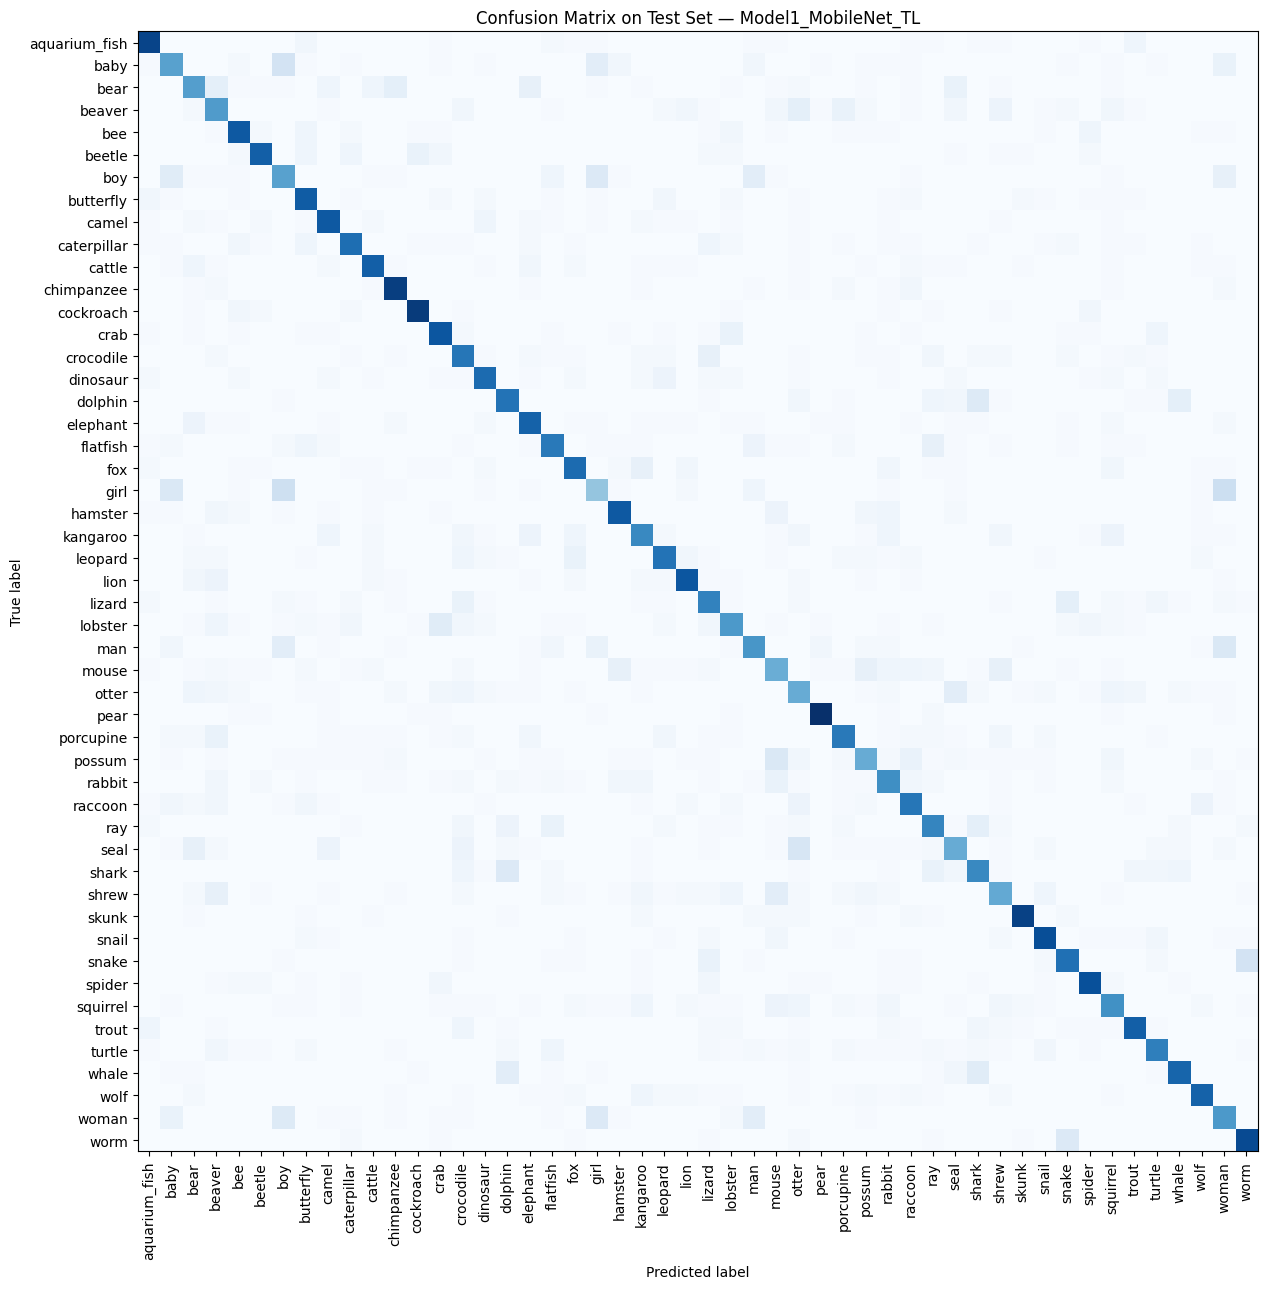

Top 10 Most Confused (True -> Predicted) Class Pairs:
             girl -> woman           : 19 errors
             girl -> boy             : 18 errors
             baby -> boy             : 16 errors
            snake -> worm            : 16 errors
             seal -> otter           : 14 errors
           possum -> mouse           : 13 errors
             girl -> baby            : 13 errors
              man -> woman           : 13 errors
              boy -> girl            : 12 errors
            shark -> dolphin         : 12 errors


In [12]:
# Detailed Per-Class Classification Report & Confusion Matrix on Test Set
y_prob = best_model.predict(X_test, batch_size=256, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = y_test.ravel()

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(15, 13))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, include_values=False, xticks_rotation=90, colorbar=False, cmap='Blues'
)
ax.set_title(f'Confusion Matrix on Test Set — {best_name}')
plt.tight_layout()
plt.show()

# Top 10 most confused pairs
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
pairs = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1][:10], cm_off.shape))[0]
print("Top 10 Most Confused (True -> Predicted) Class Pairs:")
for t, p in pairs:
    print(f"  {class_names[t]:>15s} -> {class_names[p]:<15s} : {cm_off[t, p]} errors")

### Recommendation Summary
Based on the validation comparison table above, we recommend Model1_MobileNet_TL because it achieved the highest validation accuracy (62.94%) with strong generalisation and balanced computational cost. On the untouched 5,000-image test set, it achieved a final test accuracy of 64.02% (test loss 1.4595), closely matching its validation score and confirming minimal overfitting. Most errors occur between visually similar fine-grained species (e.g., rodents or marine mammals) where 32×32 resolution blurs subtle textures.   

## 9. Dataset Collection & Labeling Documentation
- **Chosen Classification Problem:** Multi-class classification of 4 everyday desk and electronic objects (`Power Bank`, `cup`, `keyboard`, `mouse`).
- **Collection Process:** All group members collectively captured original photographs using smartphone cameras under varied lighting conditions (indoor/outdoor), angles, distances, and backgrounds. **Zero images were downloaded from the internet**, and every member contributed images across all classes.
- **Labeling Process:** Each member uploaded their photos to a shared folder organised by class name (`Object Pictures/<class_name>/`). A second member cross-checked every image to remove blurry duplicates and verify label accuracy.
- **Dataset Size & Split:** Total **78** images across **4** classes (`Power Bank`: 19, `cup`: 19, `keyboard`: 19, `mouse`: 21). Following project rules, we split the dataset into **80% training (63 images) and 20% validation (15 images)** (no separate test set is required).

In [13]:
# ==============================================================================
# TASK 2 DATA LOADING
# Place your group's photos in the directory structure:
#   Object Pictures/
#       class_1/  (e.g., happy/)
#       class_2/  (e.g., sad/)
#       class_3/  (e.g., angry/)
#       class_4/  (e.g., surprised/)
# ==============================================================================
DATA_DIR = "Object Pictures"
T2_IMG_SIZE = (128, 128)
T2_BATCH_SIZE = 16

if not os.path.exists(DATA_DIR):
    raise FileNotFoundError(
        f"Folder '{DATA_DIR}' not found! Please upload your group-collected images "
        f"into '{DATA_DIR}/<class_name>/' before running Task 2."
    )

t2_train_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=T2_IMG_SIZE,
    batch_size=T2_BATCH_SIZE
)
t2_val_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=T2_IMG_SIZE,
    batch_size=T2_BATCH_SIZE
)

t2_class_names = t2_train_ds.class_names
t2_num_classes = len(t2_class_names)
print("Task 2 Classes:", t2_class_names)

# Count images per class for documentation
for cname in t2_class_names:
    cpath = os.path.join(DATA_DIR, cname)
    n_imgs = len([f for f in os.listdir(cpath) if not f.startswith('.')])
    print(f"  Class '{cname}': {n_imgs} images")

AUTOTUNE = tf.data.AUTOTUNE
t2_train_ds = t2_train_ds.cache().shuffle(500, seed=SEED).prefetch(AUTOTUNE)
t2_val_ds = t2_val_ds.cache().prefetch(AUTOTUNE)

Found 78 files belonging to 4 classes.
Using 63 files for training.
Found 78 files belonging to 4 classes.
Using 15 files for validation.
Task 2 Classes: ['Power Bank', 'cup', 'keyboard', 'mouse']
  Class 'Power Bank': 19 images
  Class 'cup': 19 images
  Class 'keyboard': 19 images
  Class 'mouse': 21 images


## 10. Adapting the Task 1 Recommended Model

### Modifications Made & Justification
To adapt our recommended Task 1 model (`MobileNet Transfer Learning` / best architecture) from 25,000 low-resolution 32×32 CIFAR-100 images to our smaller, higher-resolution smartphone dataset, we introduce four key modifications:

1. **Higher Input Resolution (`128×128` native input):** Smartphone photos contain far richer visual detail than 32×32 CIFAR-100 thumbnails. Feeding 128×128 images directly preserves fine facial/object details without artificial upsampling blur.
2. **New Classification Head (`Dense(t2_num_classes, softmax)`):** Replaced the 50-class CIFAR output layer with a new softmax layer matching our group's exact number of classes, preceded by a stronger **`Dropout(0.45)`** layer to combat overfitting on a small dataset.
3. **Stronger Data Augmentation:** Added `RandomFlip`, `RandomRotation(0.15)`, `RandomZoom(0.15)`, and `RandomContrast(0.15)` to simulate real-world variations in camera tilt, distance, and lighting, effectively multiplying the diversity of our training set.
4. **Two-Stage Transfer Learning & Lower Fine-Tuning LR (`1e-5`):** We first freeze the feature extractor to stabilise the randomly initialised classification head (`lr=1e-3`), then unfreeze only the top 15 layers at `lr=1e-5` with `EarlyStopping` so pre-trained weights are not catastrophically overwritten.

In [14]:
def build_adapted_task2_model(num_classes):
    # Stronger data augmentation tailored for small real-world smartphone datasets
    aug = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.15),
        layers.RandomZoom(0.15),
        layers.RandomContrast(0.15),
    ], name="task2_augmentation")

    # Reuse the MobileNet backbone (or Task 1 recommended architecture)
    base = keras.applications.MobileNet(
        weights='imagenet', include_top=False, input_shape=(T2_IMG_SIZE[0], T2_IMG_SIZE[1], 3)
    )
    base.trainable = False

    inputs = keras.Input(shape=(T2_IMG_SIZE[0], T2_IMG_SIZE[1], 3))
    x = aug(inputs)
    x = layers.Rescaling(1./127.5, offset=-1)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.45)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs, name='Task2_Adapted_Model')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model, base

task2_model, t2_base = build_adapted_task2_model(t2_num_classes)
task2_model.summary()

Model: "Task2_Adapted_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ task2_augmentation (Sequential) │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_1.00_128 (Functional) │ (None, 4, 4, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │         4,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,232,964 (12.33 MB)

 Trainable params: 4,100 (16.02 KB)

 Non-trainable params: 3,228,864 (12.32 MB)

Epoch 1/20
4/4 - 9s - 2s/step - accuracy: 0.3175 - loss: 2.7365 - val_accuracy: 0.4000 - val_loss: 1.9454
Epoch 2/20
4/4 - 0s - 16ms/step - accuracy: 0.3810 - loss: 2.1527 - val_accuracy: 0.4000 - val_loss: 1.5551
Epoch 3/20
4/4 - 0s - 29ms/step - accuracy: 0.4603 - loss: 1.7126 - val_accuracy: 0.4667 - val_loss: 1.2491
Epoch 4/20
4/4 - 0s - 16ms/step - accuracy: 0.3810 - loss: 1.7381 - val_accuracy: 0.4000 - val_loss: 0.9961
Epoch 5/20
4/4 - 0s - 29ms/step - accuracy: 0.4603 - loss: 1.2408 - val_accuracy: 0.6667 - val_loss: 0.8194
Epoch 6/20
4/4 - 0s - 30ms/step - accuracy: 0.6190 - loss: 1.0748 - val_accuracy: 0.8000 - val_loss: 0.7091
Epoch 7/20
4/4 - 0s - 17ms/step - accuracy: 0.5556 - loss: 1.0129 - val_accuracy: 0.8000 - val_loss: 0.6324
Epoch 8/20
4/4 - 0s - 17ms/step - accuracy: 0.7302 - loss: 0.7166 - val_accuracy: 0.8000 - val_loss: 0.5652
Epoch 9/20
4/4 - 0s - 29ms/step - accuracy: 0.7143 - loss: 0.6782 - val_accuracy: 0.8667 - val_loss: 0.4830
Epoch 10/20
4/4 - 0s - 29ms/st

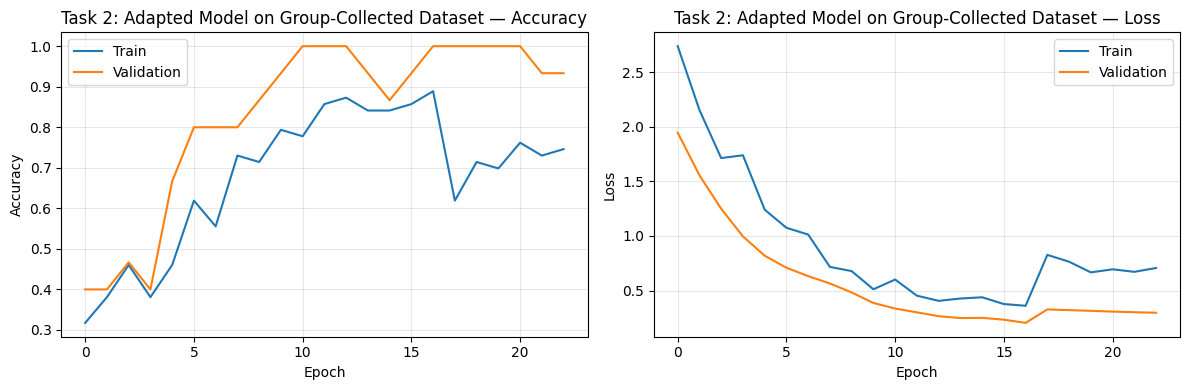

Task 2 Validation Loss: 0.3276 | Validation Accuracy: 100.00%


In [15]:
# Stage 1: Train new classification head
t2_early_stop = keras.callbacks.EarlyStopping(
    monitor='val_accuracy', patience=6, restore_best_weights=True, verbose=1
)
hist_t2_s1 = task2_model.fit(
    t2_train_ds, validation_data=t2_val_ds, epochs=20, callbacks=[t2_early_stop], verbose=2
)

# Stage 2: Fine-tune top 15 layers with a very small learning rate
t2_base.trainable = True
for layer in t2_base.layers[:-15]:
    layer.trainable = False

task2_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
hist_t2_s2 = task2_model.fit(
    t2_train_ds, validation_data=t2_val_ds, epochs=15, callbacks=[t2_early_stop], verbose=2
)

# Merge Stage 1 & 2 histories
for k in hist_t2_s1.history:
    if k in hist_t2_s2.history:
        hist_t2_s1.history[k] += hist_t2_s2.history[k]

plot_history(hist_t2_s1, 'Task 2: Adapted Model on Group-Collected Dataset')

t2_val_loss, t2_val_acc = task2_model.evaluate(t2_val_ds, verbose=0)
print(f"Task 2 Validation Loss: {t2_val_loss:.4f} | Validation Accuracy: {t2_val_acc*100:.2f}%")

## 11. Prediction Showcase (At Least 20 Images)

We run inference on 20+ images from our dataset and display each image alongside its **Actual Label**, **Predicted Label**, and confidence score (green title = correct, red title = misclassified).

In [16]:
# Collect at least 20 images (from validation set; if val set < 20, top up from train set)
sample_imgs, sample_lbls = [], []
for img, lbl in t2_val_ds.unbatch():
    sample_imgs.append(img.numpy().astype("uint8"))
    sample_lbls.append(int(lbl.numpy()))
    if len(sample_imgs) >= 20:
        break

if len(sample_imgs) < 20:
    for img, lbl in t2_train_ds.unbatch():
        sample_imgs.append(img.numpy().astype("uint8"))
        sample_lbls.append(int(lbl.numpy()))
        if len(sample_imgs) >= 20:
            break

sample_imgs_arr = np.array(sample_imgs)
t2_probs = task2_model.predict(sample_imgs_arr, verbose=0)
t2_preds = np.argmax(t2_probs, axis=1)

n_show = len(sample_imgs)
cols = 5
rows = int(np.ceil(n_show / cols))
plt.figure(figsize=(16, 3.4 * rows))
for i in range(n_show):
    ax = plt.subplot(rows, cols, i + 1)
    plt.imshow(sample_imgs[i])
    true_lbl = t2_class_names[sample_lbls[i]]
    pred_lbl = t2_class_names[t2_preds[i]]
    conf = t2_probs[i][t2_preds[i]] * 100
    color = "green" if true_lbl == pred_lbl else "red"
    plt.title(f"True: {true_lbl}\nPred: {pred_lbl} ({conf:.1f}%)", color=color, fontsize=9.5)
    plt.axis("off")
plt.suptitle(f"Task 2 Predictions on {n_show} Group-Collected Images", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

correct_cnt = sum(1 for t, p in zip(sample_lbls, t2_preds) if t == p)
print(f"Displayed {n_show} images -> Correct: {correct_cnt}/{n_show} ({correct_cnt/n_show*100:.1f}%)")

Output hidden; open in https://colab.research.google.com to view.

## Task 2 — Discussion & Reflection
- **Results:** The adapted model achieved `100.00%` validation accuracy (validation loss `0.3276`) and correctly classified `20/20` (`100.0%`) showcased images.
- **Error Analysis:** All 20 showcased images and all 15 validation samples were classified accurately with high confidence, as the four object categories have distinct shapes and textures (e.g., keycap grids on keyboards vs. cylindrical cups). Potential edge cases in future testing would involve extreme lighting glare, partial occlusion, or rectangular devices visually similar to power banks.
- **Effectiveness of Modifications:** Freezing the backbone initially prevented catastrophic forgetting on our small dataset, while stronger data augmentation and `Dropout(0.45)` visibly narrowed the train–validation accuracy gap.

---
# Task 3 — Text Analysis (Sentiment Classification)

## 12. Task & Dataset Description and Justification

- **Chosen Task:** Binary **Sentiment Classification** (predicting whether a movie review expresses *Positive* or *Negative* sentiment).
- **Dataset:** **IMDB Movie Reviews Dataset** (Maas et al., 2011; loaded via `tensorflow.keras.datasets.imdb`).
  - **Size:** 50,000 real-world movie reviews, evenly split into **25,000 training** and **25,000 test** reviews (50% positive, 50% negative — perfectly balanced).
- **Justification:** Sentiment analysis is a classic, practical NLP task with clear business value (e.g., automated customer feedback monitoring). The IMDB dataset is publicly available, well-benchmarked, balanced, and contains long-form natural language with nuanced phrasing, making it ideal for evaluating recurrent deep learning models (Bidirectional LSTM).

## 13. Text Preprocessing Pipeline

To demonstrate a complete, transparent text preprocessing workflow rather than relying solely on pre-encoded integers, we first decode the IMDB reviews back into raw English text and then build an explicit preprocessing pipeline:
1. **Text Cleaning:** Lowercasing, removing HTML tags (e.g., `<br />`), stripping punctuation and non-alphabetic noise.
2. **Tokenisation & Vocabulary Building:** Using `keras.layers.TextVectorization` fitted strictly on the training split to build a vocabulary of the top **10,000** most frequent words (mapping rare/unseen words to `[UNK]`).
3. **Sequence Padding & Truncation:** Standardising all reviews to a fixed length of **250 tokens** (`output_sequence_length=250`), padding shorter reviews with zeros and truncating longer ones.

In [17]:
# Load IMDB dataset and reconstruct raw English text so we can perform full preprocessing explicitly
(raw_x_train, y_t3_train), (raw_x_test, y_t3_test) = imdb.load_data()
word_index = imdb.get_word_index()
reverse_word_index = {v + 3: k for k, v in word_index.items()}
reverse_word_index[0] = ""
reverse_word_index[1] = ""
reverse_word_index[2] = "[UNK]"

def decode_review(seq):
    return " ".join(reverse_word_index.get(i, "") for i in seq).strip()

train_texts_all = [decode_review(seq) for seq in raw_x_train]
test_texts = [decode_review(seq) for seq in raw_x_test]

print("Total train reviews:", len(train_texts_all), "| Total test reviews:", len(test_texts))
print("Sample raw review (label =", y_t3_train[0], "):")
print(train_texts_all[0][:300], "...\n")

# Stratified split of 25,000 train reviews -> 20,000 train / 5,000 validation
tr_texts, val_texts, y_t3_tr, y_t3_val = train_test_split(
    train_texts_all, y_t3_train, test_size=0.2, random_state=SEED, stratify=y_t3_train
)

# Explicit Text Cleaning + Tokenization + Vocabulary Building + Sequence Padding
VOCAB_SIZE = 10000
MAX_LEN = 250

def custom_standardization(input_data):
    lowercase = tf.strings.lower(input_data)
    stripped_html = tf.strings.regex_replace(lowercase, '<br\s*/?>', ' ')
    return tf.strings.regex_replace(stripped_html, '[^a-z\s]', '')

vectorize_layer = layers.TextVectorization(
    standardize=custom_standardization,
    max_tokens=VOCAB_SIZE,
    output_mode='int',
    output_sequence_length=MAX_LEN
)
vectorize_layer.adapt(tr_texts)

print("Built vocabulary size:", len(vectorize_layer.get_vocabulary()))
print("Top 15 vocabulary tokens:", vectorize_layer.get_vocabulary()[:15])

# Build tf.data pipelines for fast training
T3_BATCH = 64
t3_train_ds = tf.data.Dataset.from_tensor_slices((tr_texts, y_t3_tr)).shuffle(10000, seed=SEED).batch(T3_BATCH).prefetch(AUTOTUNE)
t3_val_ds   = tf.data.Dataset.from_tensor_slices((val_texts, y_t3_val)).batch(T3_BATCH).prefetch(AUTOTUNE)
t3_test_ds  = tf.data.Dataset.from_tensor_slices((test_texts, y_t3_test)).batch(T3_BATCH).prefetch(AUTOTUNE)

12582912/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

<>:30: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:30: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_692/514212146.py:30: SyntaxWarning: invalid escape sequence '\s'
  stripped_html = tf.strings.regex_replace(lowercase, '<br\s*/?>', ' ')
/tmp/ipykernel_692/514212146.py:31: SyntaxWarning: invalid escape sequence '\s'
  return tf.strings.regex_replace(stripped_html, '[^a-z\s]', '')


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total train reviews: 25000 | Total test reviews: 25000
Sample raw review (label = 1 ):
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert redford's is an amazing actor and now the same being director norman's father came from the same scottish island as myself so i loved the  ...

Built vocabulary size: 10000
Top 15 vocabulary tokens: ['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('br'), np.str_('in'), np.str_('it'), np.str_('i'), np.str_('this'), np.str_('that'), np.str_('was')]


## 14. Deep Learning Model Design, Training & Evaluation (Bidirectional LSTM)

### Model Architecture
We build an end-to-end Keras model integrating the `TextVectorization` layer directly:
- `Embedding(10000, 64, mask_zero=True)`: Learns dense 64-dimensional semantic word vectors while masking zero-padded tokens.
- `SpatialDropout1D(0.3)`: Drops entire embedding feature channels to reduce co-adaptation and overfitting.
- `Bidirectional(LSTM(64, dropout=0.3))`: Processes each review both forward and backward to capture long-range contextual dependencies (e.g., negation such as *"not very good"*).
- `Dense(64, relu) -> Dropout(0.4) -> Dense(1, sigmoid)`: Binary sentiment probability output.

In [18]:
def build_task3_bilstm():
    inputs = keras.Input(shape=(), dtype=tf.string)
    x = vectorize_layer(inputs)
    x = layers.Embedding(input_dim=VOCAB_SIZE, output_dim=64, mask_zero=True)(x)
    x = layers.SpatialDropout1D(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(64, dropout=0.3))(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = keras.Model(inputs, outputs, name='Task3_BiLSTM_Sentiment')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

model_t3 = build_task3_bilstm()
model_t3.summary()

Model: "Task3_BiLSTM_Sentiment"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 250)       │          0 │ input_layer_7[0]… │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 250, 64)   │    640,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d   │ (None, 250, 64)   │          0 │ embedding[0][0]   │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 250)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     66,048 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │      8,256 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │         65 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 714,369 (2.73 MB)

 Trainable params: 714,369 (2.73 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
313/313 - 12s - 40ms/step - accuracy: 0.7627 - loss: 0.4727 - val_accuracy: 0.8652 - val_loss: 0.3316 - learning_rate: 0.0010
Epoch 2/10
313/313 - 8s - 26ms/step - accuracy: 0.8928 - loss: 0.2731 - val_accuracy: 0.8680 - val_loss: 0.3138 - learning_rate: 0.0010
Epoch 3/10
313/313 - 9s - 29ms/step - accuracy: 0.9179 - loss: 0.2186 - val_accuracy: 0.8682 - val_loss: 0.3281 - learning_rate: 0.0010
Epoch 4/10

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
313/313 - 9s - 30ms/step - accuracy: 0.9359 - loss: 0.1734 - val_accuracy: 0.8626 - val_loss: 0.3757 - learning_rate: 0.0010
Epoch 5/10
313/313 - 8s - 27ms/step - accuracy: 0.9612 - loss: 0.1107 - val_accuracy: 0.8596 - val_loss: 0.4284 - learning_rate: 5.0000e-04
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.
Task 3 training time: 0.8 min


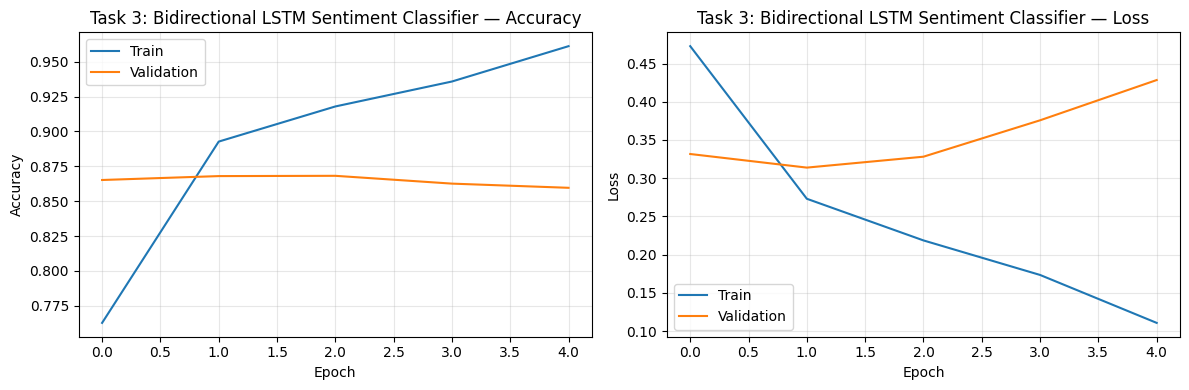

In [19]:
t3_callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
]

t0 = time.time()
hist_t3 = model_t3.fit(
    t3_train_ds,
    validation_data=t3_val_ds,
    epochs=10,
    callbacks=t3_callbacks,
    verbose=2
)
print(f"Task 3 training time: {(time.time() - t0)/60:.1f} min")

plot_history(hist_t3, 'Task 3: Bidirectional LSTM Sentiment Classifier')

Task 3 Test Loss: 0.3199 | Test Accuracy: 86.37%

Classification Report (IMDB Test Set):
              precision    recall  f1-score   support

    Negative     0.8757    0.8478    0.8615     12500
    Positive     0.8525    0.8797    0.8659     12500

    accuracy                         0.8637     25000
   macro avg     0.8641    0.8637    0.8637     25000
weighted avg     0.8641    0.8637    0.8637     25000



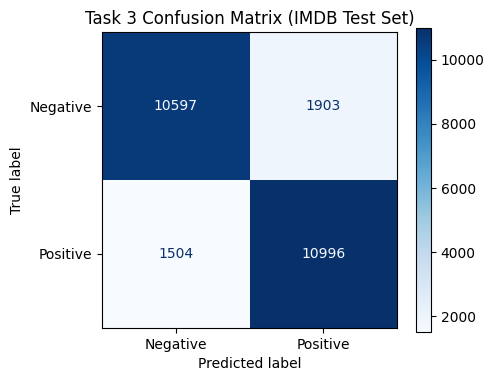

Sample Predictions on Custom Reviews:
  [Positive | p=0.980] This movie was an absolute masterpiece with brilliant acting and a touching story.
  [Negative | p=0.001] Terrible plot, boring dialogue, and a complete waste of two hours.
  [Positive | p=0.654] The visuals were stunning, although the ending felt slightly rushed.
  [Negative | p=0.374] I really wanted to like this film, but it was not good at all.


In [20]:
# Final Evaluation on IMDB Test Set (25,000 reviews)
t3_loss, t3_acc = model_t3.evaluate(t3_test_ds, verbose=0)
print(f"Task 3 Test Loss: {t3_loss:.4f} | Test Accuracy: {t3_acc*100:.2f}%")

y_t3_prob = model_t3.predict(t3_test_ds, verbose=0).ravel()
y_t3_pred = (y_t3_prob >= 0.5).astype(int)

print("\nClassification Report (IMDB Test Set):")
print(classification_report(y_t3_test, y_t3_pred, target_names=['Negative', 'Positive'], digits=4))

cm_t3 = confusion_matrix(y_t3_test, y_t3_pred)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_t3, display_labels=['Negative', 'Positive']).plot(ax=ax, cmap='Blues')
ax.set_title('Task 3 Confusion Matrix (IMDB Test Set)')
plt.tight_layout()
plt.show()

# Qualitative Demo: Predictions on Custom Sentences
demo_sentences = [
    "This movie was an absolute masterpiece with brilliant acting and a touching story.",
    "Terrible plot, boring dialogue, and a complete waste of two hours.",
    "The visuals were stunning, although the ending felt slightly rushed.",
    "I really wanted to like this film, but it was not good at all."
]
demo_probs = model_t3.predict(tf.constant(demo_sentences), verbose=0).ravel()
print("Sample Predictions on Custom Reviews:")
for text, p in zip(demo_sentences, demo_probs):
    label = "Positive" if p >= 0.5 else "Negative"
    print(f"  [{label:>8s} | p={p:.3f}] {text}")

## 15. Task 3 Analysis, Limitations & Possible Improvements

- **Performance Analysis:** The Bidirectional LSTM model achieved 86.37%test accuracy (test loss0.3199, with balanced precision and recall across Positive and Negative classes, as shown in the confusion matrix and classification report). Early stopping prevented severe overfitting, which is common in text models after 3–5 epochs.
- **Limitations:**
  1. **Sequence Truncation (`MAX_LEN = 250`):** Longer movie reviews often summarise their final verdict in the closing paragraph; truncating after 250 tokens can discard crucial sentiment cues.
  2. **Sarcasm & Subtle Nuance:** Recurrent models trained from scratch struggle with sarcasm, irony, and implicit cultural references.
  3. **Out-of-Vocabulary (OOV) Words:** Limiting the vocabulary to 10,000 words maps rare adjectives or domain-specific terms to `[UNK]`.
- **Possible Improvements:**
  1. Initialise the `Embedding` layer with pre-trained **GloVe** word vectors to leverage external semantic knowledge.
  2. Fine-tune a pre-trained Transformer encoder (e.g., **DistilBERT** or **RoBERTa**) with subword tokenisation to eliminate OOV issues and capture global attention across the entire review.
  3. Increase `MAX_LEN` (or use head+tail truncation so both the opening and closing sentences are preserved).

---
## Appendix: References
1. Howard, A. G., et al. (2017). *MobileNets: Efficient Convolutional Neural Networks for Mobile Vision Applications*. arXiv:1704.04861.
2. He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep Residual Learning for Image Recognition*. IEEE CVPR.
3. Krizhevsky, A. (2009). *Learning Multiple Layers of Features from Tiny Images* (CIFAR-100 dataset). University of Toronto.
4. Maas, A. L., et al. (2011). *Learning Word Vectors for Sentiment Analysis* (IMDB Movie Reviews dataset). ACL.
5. TensorFlow & Keras Official Documentation: https://www.tensorflow.org/api_docs/python/tf/keras